# 01 - Data acquisition and EDA
Heart Disease UCI (Cleveland). Run `python scripts/download_data.py` first.

In [1]:
%pip install pandas seaborn matplotlib

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (137 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (9.9 MB)
Using cached contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (383 kB)
Using cache

In [2]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from src.heart.data import load_clean, NUMERIC_FEATURES, CATEGORICAL_FEATURES, TARGET
df = load_clean()
print(df.shape); df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
print(df.isna().sum()[lambda s: s > 0])   # missing values (ca, thal) - imputed inside the pipeline
df.describe().T.round(2)

ca      4
thal    2
dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


target
0    0.541
1    0.459
Name: proportion, dtype: float64

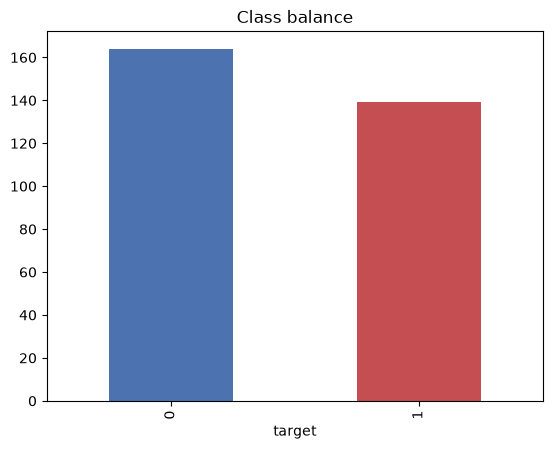

In [4]:
ax = df[TARGET].value_counts().sort_index().plot.bar(color=['#4c72b0','#c44e52'])
ax.set_title('Class balance'); df[TARGET].value_counts(normalize=True).round(3)

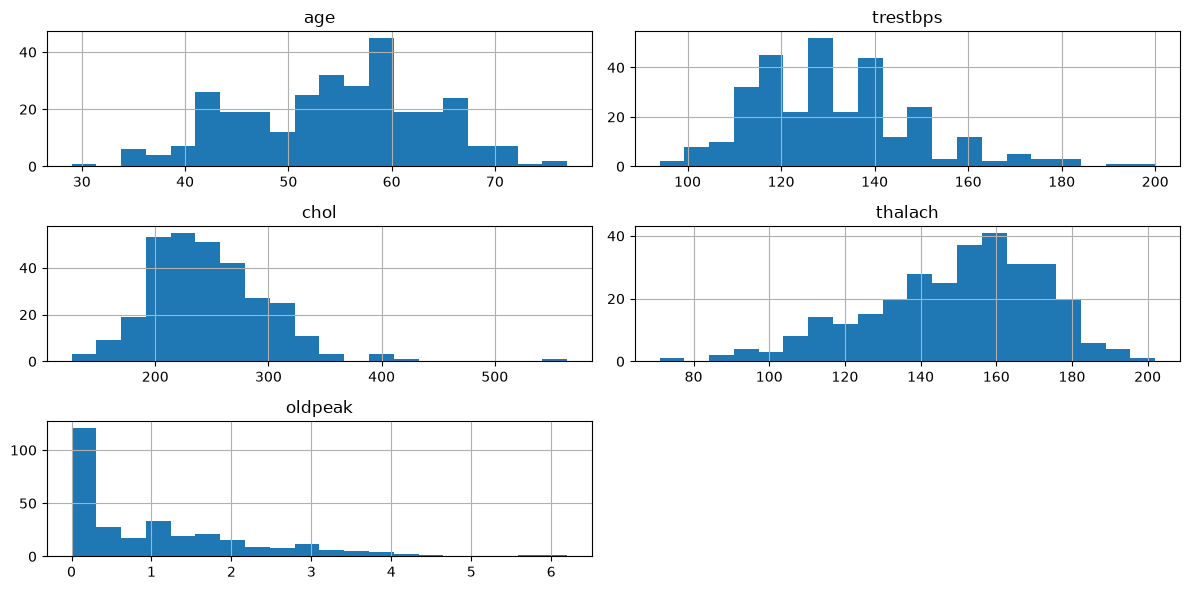

In [5]:
df[NUMERIC_FEATURES].hist(bins=20, figsize=(12, 6)); plt.tight_layout()

thal        0.526
ca          0.460
exang       0.432
oldpeak     0.425
thalach    -0.417
cp          0.414
slope       0.339
sex         0.277
age         0.223
restecg     0.169
trestbps    0.151
chol        0.085
fbs         0.025
Name: target, dtype: float64

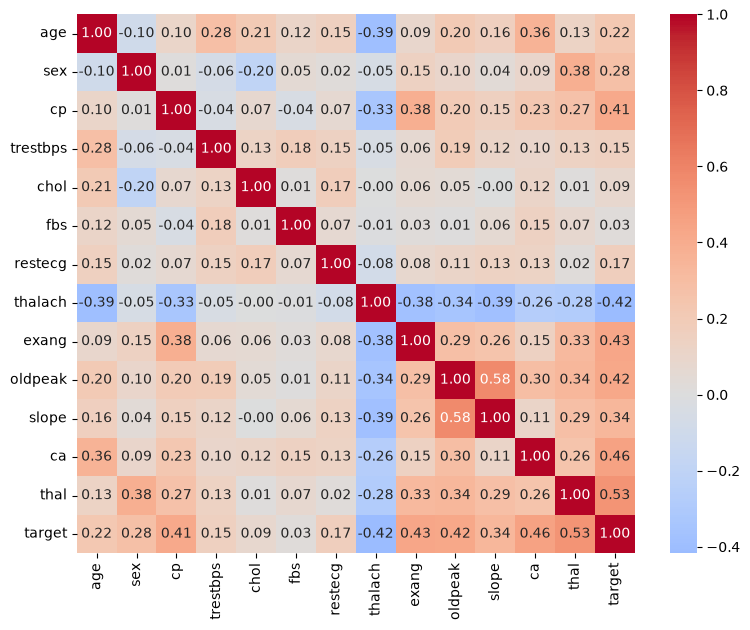

In [6]:
plt.figure(figsize=(9, 7)); sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
df.corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3)

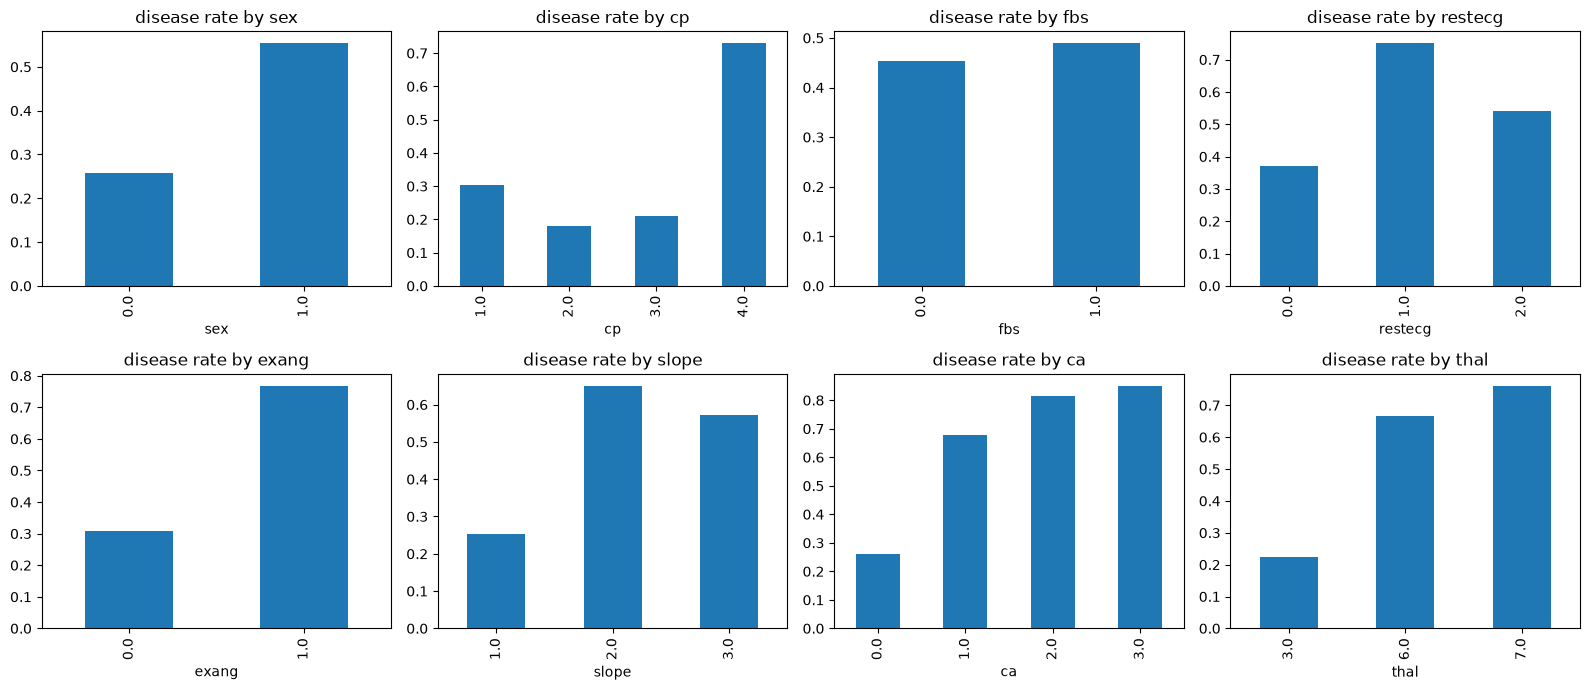

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), CATEGORICAL_FEATURES):
    df.groupby(c)[TARGET].mean().plot.bar(ax=ax, title=f'disease rate by {c}')
plt.tight_layout()

**Findings:** classes are near-balanced (54/46). Strongest signals: `thal`, `ca`, `exang`, `oldpeak`, `thalach` (negative), `cp`. `chol` and `fbs` are weak. A few IQR outliers in `chol`, `oldpeak`, `trestbps` are kept (clinically plausible).